In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from numpy.polynomial import Polynomial
from pyspan.io import read_ta_dat, read_ab_dat
from pyspan.utils import between, rescale
from pyspan.itos import load_itos_spectrum
import pyspan
from glob import glob

In [2]:
import pyspan

In [2]:
%matplotlib widget

In [3]:
wl, itos = np.loadtxt("ITOS_240724.dat").T
wl_org = wl.copy()
wl_ref, spec_ref = load_itos_spectrum()
lo = max(np.min(wl), np.min(wl_ref))
hi = min(np.max(wl), np.max(wl_ref))
m_d = between(wl, lo, hi)
m_r = between(wl_ref, lo, hi)
wl = wl.compress(m_d)
itos = itos.compress(m_d)
wl_ref = wl_ref.compress(m_r)
spec_ref = spec_ref.compress(m_r)

FileNotFoundError: ITOS_240724.dat not found.

# Know peak positions
357, 471, 526, 583.5, 680, 744, 803, 875

In [4]:
kwargs = dict(width=4, height=80)
peak_ref, _ = find_peaks(spec_ref, **kwargs)
peaks, _ = find_peaks(itos, **kwargs)

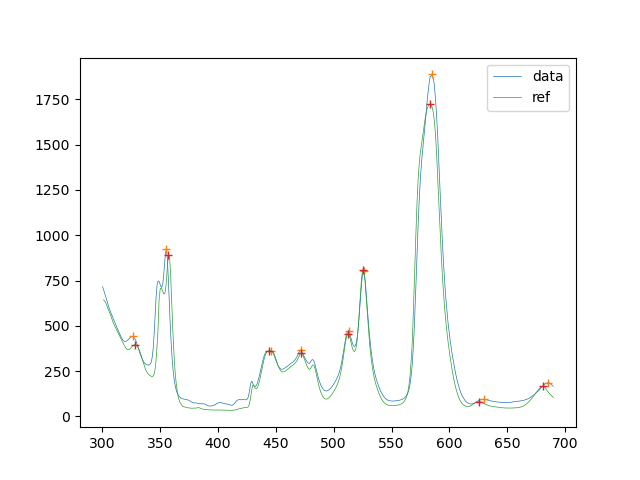

In [5]:
plt.figure()
plt.plot(wl, itos, lw=0.5, label="data")
plt.plot(wl[peaks], itos[peaks], "+")
plt.plot(wl_ref, spec_ref, lw=0.5, label="ref")
plt.plot(wl_ref[peak_ref], spec_ref[peak_ref], "+")
plt.legend()

In [6]:
assigned = wl_ref[peak_ref]
observed = wl[peaks]
#pol = np.polyfit(observed, assigned, deg=1)
pol = Polynomial.fit(observed, assigned, 1).convert()
fitted = pol(observed)
wl_corr = pol(wl_org)
r2 = 1-np.sum((observed-fitted)**2)/np.var(observed)
pol

Polynomial([7.95167888, 0.98219286], domain=[-1.,  1.], window=[-1.,  1.], symbol='x')

In [7]:
r2

0.9964000684786056

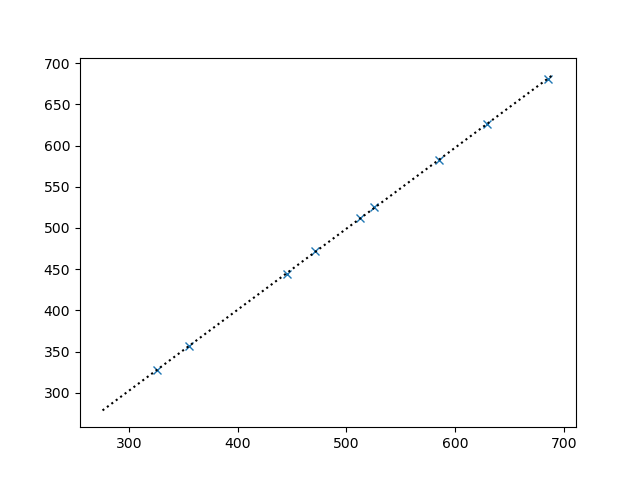

In [8]:
plt.figure()

plt.plot(observed, assigned, "x")
plt.plot(wl_org, wl_corr, ":k")


In [9]:
np.savetxt("wl_corr.txt", np.vstack([wl_org, wl_corr]).T, fmt="%.04e", header="measured (nm)\tcal (nm)")

In [12]:
corr_fn = [fn for fn in glob("*_lin_*dat") if "ITOS" not in fn]
for fn in corr_fn:
    if "_lin" in fn:
        dat = np.loadtxt(fn)
        assert np.allclose(dat[:,0], wl_org)
        dat[:,0] = wl_corr
    else:
        dat = np.loadtxt(fn)
        assert np.allclose(dat[1:,0], wl)
        dat[1:,0] = wl_corr
    np.savetxt(fn, dat, fmt="%.06e")